# Cleaning Data
**Oasis Infobyte SIP — Data Analytics L1 Task 3** · Steven Manuel Rios

The source is the **Titanic** dataset (891 passengers, seaborn-data copy). Real-world messiness is reproduced on top of its natural problems (missing `age`, `deck` and `embarked`) with a seeded, documented step, so every cleaning step has something to fix:
* inconsistent sex labels (`Male`, `m`, `F `, ...)
* fares stored as strings with currency symbols
* a mix of three date formats in a synthetic `booking_date` column
* passenger IDs stored as floats
* 25 duplicated rows and a few impossible ages and fares

The messy file is saved to `data/titanic_messy.csv` so the cleaning can be rerun from it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
rng = np.random.default_rng(7)
raw = pd.read_csv("data/titanic_raw.csv")
m = raw.copy()
m.insert(0, "passenger_id", np.arange(1, len(m) + 1).astype(float))
m["sex"] = [rng.choice({"male": ["male", "Male", "M", "m", " male"], "female": ["female", "Female", "F", "f", "female "]}[s]) for s in m["sex"]]
m["fare"] = ["$" + f"{f:,.2f}" if rng.random() < .3 else f"{f}" for f in m["fare"]]
d = pd.Timestamp("1912-01-01") + pd.to_timedelta(rng.integers(0, 95, len(m)), unit="D")
fmts = ["%Y-%m-%d", "%d/%m/%Y", "%B %d, %Y"]
m["booking_date"] = [x.strftime(fmts[rng.integers(0, 3)]) for x in d]
idx = rng.choice(len(m), 4, replace=False); m.loc[idx[:2], "age"] = [-1, 250]
m.loc[idx[2:], "fare"] = ["-5", "99999"]
m = pd.concat([m, m.sample(25, random_state=1)]).sample(frac=1, random_state=2).reset_index(drop=True)
m.to_csv("data/titanic_messy.csv", index=False)

## 1. Data quality report

In [3]:
df = pd.read_csv("data/titanic_messy.csv")
def quality(d):
    return pd.DataFrame({"dtype": d.dtypes.astype(str), "nulls": d.isnull().sum(), "null_%": (d.isnull().mean() * 100).round(1), "unique": d.nunique()})
print("Rows:", len(df), "| duplicate rows:", df.duplicated().sum())
quality(df)

Rows: 916 | duplicate rows: 25


,dtype,nulls,null_%,unique
passenger_id,float64,0,0.0,891
survived,int64,0,0.0,2
pclass,int64,0,0.0,3
sex,str,0,0.0,10
age,float64,181,19.8,90
sibsp,int64,0,0.0,7
parch,int64,0,0.0,7
fare,str,0,0.0,343
embarked,str,2,0.2,3
class,str,0,0.0,3


In [4]:
print("sex labels:", df["sex"].unique())
print("fare samples:", df["fare"].sample(6, random_state=0).tolist())
print("booking_date samples:", df["booking_date"].head(6).tolist())
print("age range:", df["age"].min(), "-", df["age"].max())

sex labels: <StringArray>
['female ', 'm', 'male', 'F', 'Male', 'female', ' male', 'M', 'Female', 'f']
Length: 10, dtype: str
fare samples: ['$6.97', '$11.24', '$7.23', '$56.50', '31.0', '$9.50']
booking_date samples: ['1912-02-18', '1912-03-28', 'January 21, 1912', '1912-01-30', '1912-02-05', 'February 29, 1912']
age range: -1.0 - 250.0


**Issues found:**
1. 25 exact duplicate rows
2. `sex` has 10 spellings for 2 values
3. `fare` is a string (`$`, `,`), with a negative value and an implausible 99999
4. `booking_date` mixes three formats
5. `age` has −1 and 250
6. `passenger_id` is stored as a float
7. `age` (~20%), `deck` (~77%) and `embarked`/`embark_town` (2 rows) are missing

`before` is snapshotted so it can be compared at the end.

In [5]:
before = {"rows": len(df), "null cells": int(df.isnull().sum().sum()), "duplicates": int(df.duplicated().sum()),
          "wrong dtypes": 3}  # passenger_id float, fare object, booking_date object
df0 = df.copy()

## 2. Duplicate removal

In [6]:
n = len(df); df = df.drop_duplicates().reset_index(drop=True); print(f"Removed {n - len(df)} duplicate rows -> {len(df)} rows")

Removed 25 duplicate rows -> 891 rows


## 3. Standardisation

In [7]:
df["sex"] = df["sex"].str.strip().str.lower().map({"male": "Male", "m": "Male", "female": "Female", "f": "Female"})
df["fare"] = df["fare"].astype(str).str.replace(r"[$,]", "", regex=True).astype(float)
df["booking_date"] = df["booking_date"].apply(lambda s: next(pd.to_datetime(s, format=f) for f in ["%Y-%m-%d", "%d/%m/%Y", "%B %d, %Y"] if not pd.isna(pd.to_datetime(s, format=f, errors="coerce"))))
print(df["sex"].value_counts(dropna=False)); df[["fare", "booking_date"]].dtypes

sex
Male      577
Female    314
Name: count, dtype: int64


fare                   float64
booking_date    datetime64[us]
dtype: object

## 4. Outlier detection (IQR + domain rules)

age: IQR bounds [-7.0, 65.0] -> 9 outliers; min=-1.0, max=250.0
fare: IQR bounds [-27.0, 66.0] -> 117 outliers; min=-5.0, max=99999.0


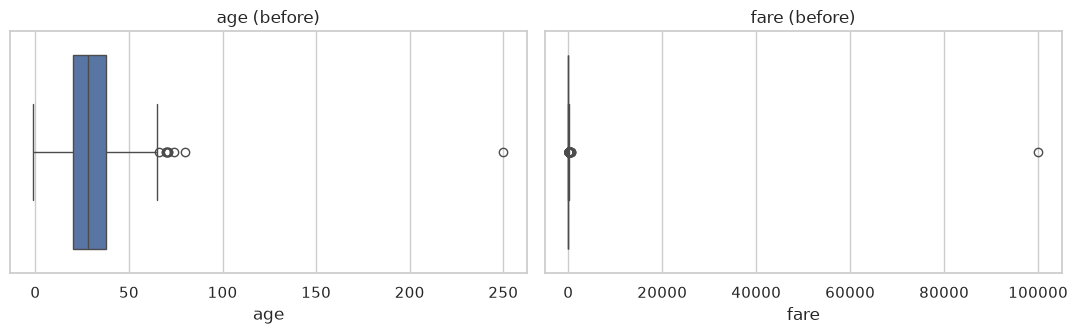

In [8]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return q1 - k * i, q3 + k * i
for col in ["age", "fare"]:
    lo, hi = iqr_bounds(df[col].dropna()); out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col}: IQR bounds [{lo:.1f}, {hi:.1f}] -> {len(out)} outliers; min={df[col].min()}, max={df[col].max()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); sns.boxplot(x=df["age"], ax=ax[0]); sns.boxplot(x=df["fare"], ax=ax[1]); ax[0].set_title("age (before)"); ax[1].set_title("fare (before)"); save("outliers_before")

**Decisions:**
* **Age −1 and 250** are impossible values (data-entry errors), so they are set to NaN and imputed with the other missing ages. The remaining IQR “outliers” (ages 60–80) are real elderly passengers and are **retained**.
* **Fare −5 and 99999** are impossible. The real maximum fare is £512.33, so they are set to NaN and imputed with the median fare of the same `pclass`.
* Fares above the IQR upper bound (~£65) are genuine first-class tickets. They are **retained**, not capped, because capping would distort the class structure.

In [9]:
df.loc[(df["age"] < 0) | (df["age"] > 100), "age"] = np.nan
df.loc[(df["fare"] < 0) | (df["fare"] > 600), "fare"] = np.nan

## 5. Missing data strategy
| Column | Strategy | Justification |
|---|---|---|
| `age` (~20%) | **median by `pclass` × `sex`** | Age is skewed and differs by class and sex, so a group median keeps those patterns. Deleting the rows would lose a fifth of the data. |
| `fare` (2 invalid) | **median by `pclass`** | Fare depends almost entirely on class. |
| `embarked`, `embark_town` (2) | **mode** (`S` / Southampton) | Categorical with 72% `S`, so the mode is the most likely value. |
| `deck` (~77%) | **fill with `Unknown`** | Too sparse to impute credibly. Missingness itself is informative (it correlates with 3rd class), so the column is kept as a category instead of being dropped. |

In [10]:
df["age"] = df.groupby(["pclass", "sex"])["age"].transform(lambda s: s.fillna(s.median()))
df["fare"] = df.groupby("pclass")["fare"].transform(lambda s: s.fillna(s.median()))
for col in ["embarked", "embark_town"]: df[col] = df[col].fillna(df[col].mode()[0])
df["deck"] = df["deck"].fillna("Unknown")
df.isnull().sum().sum()

np.int64(0)

## 6. Data type correction

In [11]:
df["passenger_id"] = df["passenger_id"].astype(int).astype(str)
for col in ["sex", "embarked", "class", "who", "deck", "embark_town", "alive"]: df[col] = df[col].astype("category")
df["survived"] = df["survived"].astype(bool); df["pclass"] = df["pclass"].astype(int)
df.dtypes

passenger_id               str
survived                  bool
pclass                   int64
sex                   category
age                    float64
sibsp                    int64
parch                    int64
fare                   float64
embarked              category
class                 category
who                   category
adult_male                bool
deck                  category
embark_town           category
alive                 category
alone                     bool
booking_date    datetime64[us]
dtype: object

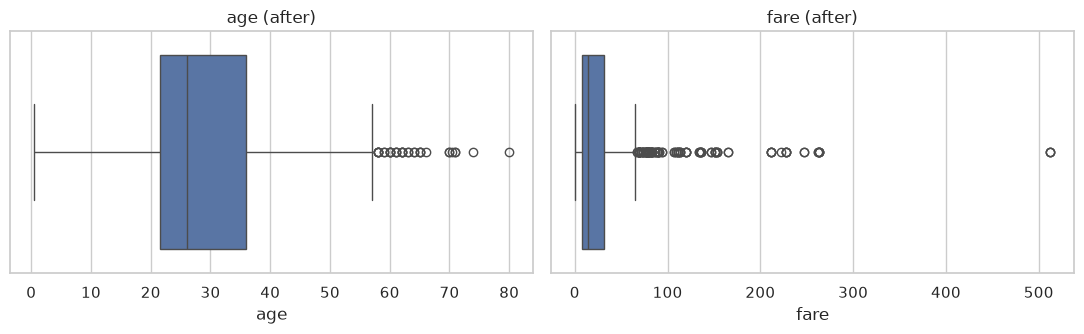

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); sns.boxplot(x=df["age"], ax=ax[0]); sns.boxplot(x=df["fare"], ax=ax[1]); ax[0].set_title("age (after)"); ax[1].set_title("fare (after)"); save("outliers_after")

## 7. Before vs after summary

In [13]:
after = {"rows": len(df), "null cells": int(df.isnull().sum().sum()), "duplicates": int(df.duplicated().sum()), "wrong dtypes": 0}
summary = pd.DataFrame({"Before": before, "After": after}); summary.loc["sex labels"] = [df0["sex"].nunique(), df["sex"].nunique()]
summary.loc["invalid age/fare values"] = [4, 0]
summary

,Before,After
rows,916,891
null cells,892,0
duplicates,25,0
wrong dtypes,3,0
sex labels,10,2
invalid age/fare values,4,0


In [14]:
df.to_csv("data/titanic_clean.csv", index=False); print("Saved data/titanic_clean.csv", df.shape)

Saved data/titanic_clean.csv (891, 17)


## Conclusion
The dataset went from 916 rows (25 duplicates), 10 sex spellings, three date formats, string-typed fares, 4 impossible values and 892 null cells to **891 unique, fully typed rows with zero nulls**. Every imputation was chosen per column so the class, sex and fare structure is preserved for later analysis.